<a href="https://colab.research.google.com/github/juliawickens3/CIND-820/blob/main/notebooks/Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

df = pd.read_csv('transit_dwell_pivoted.csv', parse_dates=['date'])

df.head()


,date,dwell_west_coast_days,e2e_transit_days
0,2017-01-01,4.3,26.3
1,2017-02-01,3.7,27.0
2,2017-03-01,2.7,24.4
3,2017-04-01,2.7,24.1
4,2017-05-01,3.5,24.3


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   93 non-null     datetime64[ns]
 1   dwell_west_coast_days  93 non-null     float64       
 2   e2e_transit_days       93 non-null     float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 2.3 KB


In [3]:
df['nondwell_days']=df['e2e_transit_days']-df['dwell_west_coast_days']

df.head()

,date,dwell_west_coast_days,e2e_transit_days,nondwell_days
0,2017-01-01,4.3,26.3,22.0
1,2017-02-01,3.7,27.0,23.3
2,2017-03-01,2.7,24.4,21.7
3,2017-04-01,2.7,24.1,21.4
4,2017-05-01,3.5,24.3,20.8


In [4]:
cols = ['e2e_transit_days', 'dwell_west_coast_days', 'nondwell_days']

df[cols].describe()

,e2e_transit_days,dwell_west_coast_days,nondwell_days
count,93.000000,93.000000,93.000000
mean,31.303226,4.423656,26.879570
std,5.607205,1.480849,4.637408
min,24.000000,1.900000,20.800000
25%,26.300000,3.400000,22.600000
50%,31.700000,4.100000,26.300000
75%,34.700000,5.400000,30.200000
max,50.000000,9.200000,42.700000


In [5]:
df[cols].var()

,0
e2e_transit_days,31.440750
dwell_west_coast_days,2.192913
nondwell_days,21.505556


In [6]:
df[cols].mode()

,e2e_transit_days,dwell_west_coast_days,nondwell_days
0,24.1,4.4,27.1
1,24.4,NaN,28.9
2,25.5,NaN,NaN
3,32.8,NaN,NaN


Text(0.5, 1.0, 'Histogram of end-to-end transit time')

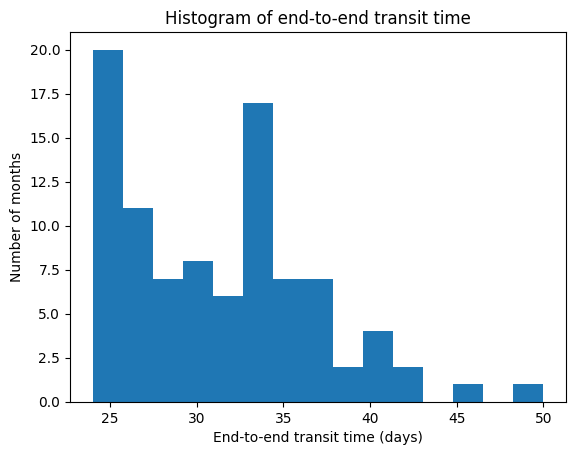

In [7]:
import matplotlib.pyplot as plt

plt.hist(df['e2e_transit_days'],bins=15)
plt.xlabel('End-to-end transit time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of end-to-end transit time')

Text(0.5, 1.0, 'Histogram of Port Dwell Time')

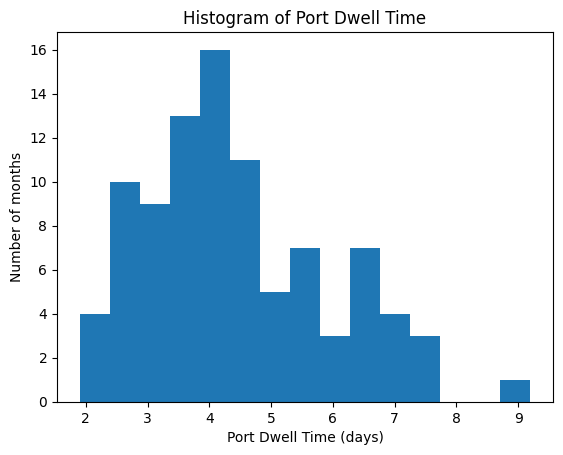

In [8]:
plt.hist(df['dwell_west_coast_days'],bins=15)
plt.xlabel('Port Dwell Time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of Port Dwell Time')

Text(0.5, 1.0, 'Histogram of transit time without port dwell')

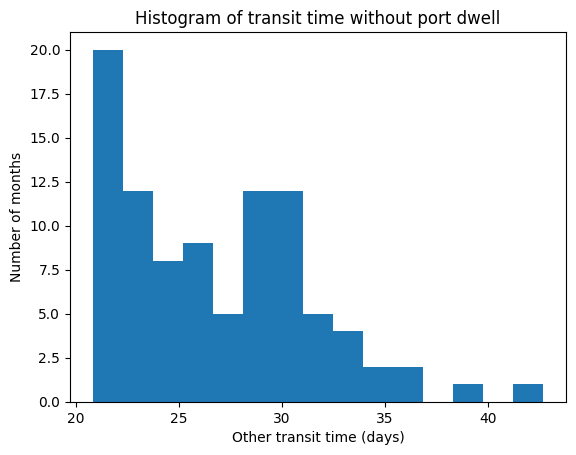

In [9]:
plt.hist(df['nondwell_days'],bins=15)
plt.xlabel('Other transit time (days)')
plt.ylabel('Number of months')
plt.title('Histogram of transit time without port dwell')

Text(0.5, 1.0, 'Boxplots of transit, dwell, and non-dwell time')

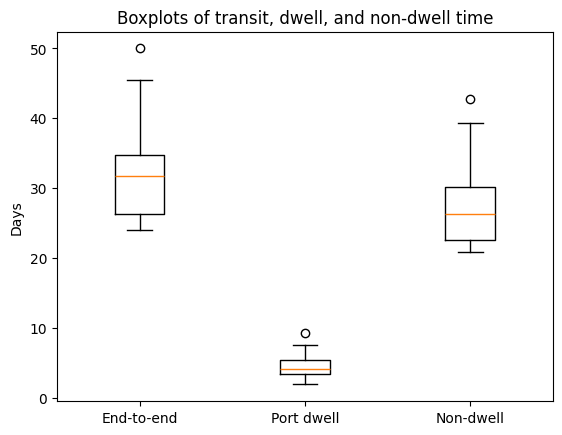

In [10]:
plt.boxplot(df[cols])
plt.xticks([1, 2, 3], ['End-to-end', 'Port dwell', 'Non-dwell'])
plt.ylabel('Days')
plt.title('Boxplots of transit, dwell, and non-dwell time')

In [11]:
def find_outliers(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return df[(df[column] < lower) | (df[column] > upper)][['date', column]]

for col in ['e2e_transit_days', 'dwell_west_coast_days', 'nondwell_days']:
    print(col)
    print(find_outliers(df, col))
    print()

e2e_transit_days
         date  e2e_transit_days
60 2022-01-01              50.0

dwell_west_coast_days
         date  dwell_west_coast_days
72 2023-01-01                    9.2

nondwell_days
         date  nondwell_days
60 2022-01-01           42.7



Text(0, 0.5, 'Transit Time (Days)')

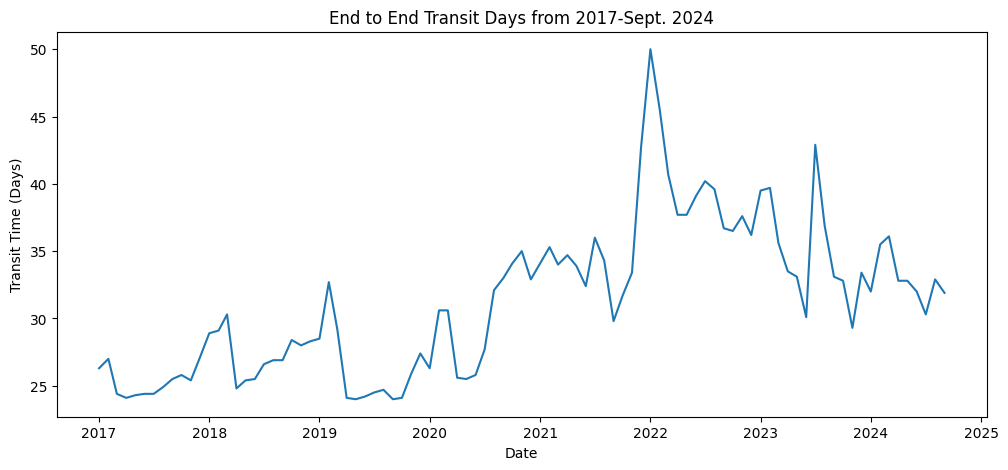

In [20]:
plt.figure(figsize=(12, 5))
plt.plot(df['date'],df['e2e_transit_days'])
plt.title('End to End Transit Days from 2017-Sept. 2024')
plt.xlabel('Date')
plt.ylabel('Transit Time (Days)')

Analysis

In [30]:
events = {
    'COVID surge': {'bench_start': 31, 'bench_end': 42, 'start': 43, 'end': 58},
    'BC floods':   {'bench_start': 47, 'bench_end': 58, 'start': 59, 'end': 61},
    'Port strike': {'bench_start': 66, 'bench_end': 77, 'start': 78, 'end': 79},
}

def benchmark_mean(df, bench_start, bench_end):
  b_mean_e2e=round(df.loc[bench_start:bench_end, 'e2e_transit_days'].mean(), 2)
  b_mean_dwell=round(df.loc[bench_start:bench_end, 'dwell_west_coast_days'].mean(),2)
  b_mean_nodwell=round(df.loc[bench_start:bench_end, 'nondwell_days'].mean(),2)
  return b_mean_e2e, b_mean_dwell, b_mean_nodwell


for name, i in events.items():
  e2e, dwell, nodwell = benchmark_mean(df, i['bench_start'], i['bench_end'])
  i['bench_e2e'] = e2e
  i['bench_dwell'] = dwell
  i['bench_nodwell'] = nodwell
  print(name, e2e, dwell, nodwell)



COVID surge 26.52 3.14 23.38
BC floods 33.54 3.47 30.07
Port strike 36.53 6.02 30.51


In [42]:
def deviation(df,events):
  window = df.loc[events['start']:events['end']]

  dev_e2e = window['e2e_transit_days'] - events['bench_e2e']
  dev_dwell = window['dwell_west_coast_days'] - events['bench_dwell']
  dev_nodwell = window['nondwell_days'] - events['bench_nodwell']

  peak_dev = dev_e2e.max()
  peak_row = dev_e2e.idxmax()
  peak_date = df.loc[peak_row, 'date']

  months_to_peak = peak_row - events['start'] + 1
  rate = peak_dev / months_to_peak

  bench_dwell_pct = events['bench_dwell'] / events['bench_e2e'] * 100
  bench_nodwell_pct = events['bench_nodwell'] / events['bench_e2e'] * 100
  dev_dwell_pct = dev_dwell.mean() / dev_e2e.mean() * 100
  dev_nodwell_pct = dev_nodwell.mean() / dev_e2e.mean() * 100

  return {
      'peak_dev': peak_dev,
      'peak_date': peak_date,
      'months_to_peak': months_to_peak,
      'rate_per_month': rate,
      'dev_e2e': dev_e2e,
      'dev_dwell': dev_dwell,
      'dev_nodwell': dev_nodwell,
      'bench_dwell_pct': bench_dwell_pct,
      'dev_dwell_pct': dev_dwell_pct,
      'bench_nodwell_pct': bench_nodwell_pct,
      'dev_nodwell_pct': dev_nodwell_pct
    }


for name, i in events.items():
  r = deviation(df, i)
  print(name, round(r['peak_dev'], 2), r['peak_date'].strftime('%Y-%m'),
        r['months_to_peak'], round(r['rate_per_month'], 2))
  print(name, round(r['bench_dwell_pct'], 1), round(r['bench_nodwell_pct'], 1),
            round(r['dev_dwell_pct'], 1), round(r['dev_nodwell_pct'], 1))


COVID surge 9.48 2021-07 12 0.79
COVID surge 11.8 88.2 7.4 92.6
BC floods 16.46 2022-01 2 8.23
BC floods 10.3 89.7 26.1 73.9
Port strike 6.37 2023-07 1 6.37
Port strike 16.5 83.5 21.7 78.3


In [45]:
def buffer_needed(dev_series, level=0.95):
    return dev_series.quantile(level, interpolation='higher')

def coverage_pct(dev_series, buffer):
    return (dev_series <= buffer).mean() * 100

for name, i in events.items():
    r = deviation(df, i)
    dev = r['dev_e2e']
    buf = buffer_needed(dev)
    print(name, len(dev), round(buf, 2), round(i['bench_e2e'] + buf, 1),
          round(coverage_pct(dev, buf), 1), round(dev.median(), 2))

COVID surge 16 9.48 36.0 100.0 7.43
BC floods 3 16.46 50.0 100.0 11.96
Port strike 2 6.37 42.9 100.0 3.37


In [49]:
def month1_and_peak(df, e):
    return dev.iloc[0], dev.max()

info = {name: month1_and_peak(df, e) for name, e in events.items()}

for held in info:
    train = [k for k in info if k != held]
    m1, actual = info[held]
    ratio = sum(info[k][1] / info[k][0] for k in train) / len(train)
    avg_peak = sum(info[k][1] for k in train) / len(train)
    preds = {'peak_first': m1, 'avg_peak': avg_peak, 'scaling': ratio * m1}
    errors = {k: abs(v - actual) for k, v in preds.items()}
    print(held, round(actual, 2), {k: round(v, 2) for k, v in preds.items()},
            {k: round(v, 2) for k, v in errors.items()})


COVID surge 6.37 {'peak_first': np.float64(6.37), 'avg_peak': 6.37, 'scaling': np.float64(6.37)} {'peak_first': np.float64(0.0), 'avg_peak': 0.0, 'scaling': np.float64(0.0)}
BC floods 6.37 {'peak_first': np.float64(6.37), 'avg_peak': 6.37, 'scaling': np.float64(6.37)} {'peak_first': np.float64(0.0), 'avg_peak': 0.0, 'scaling': np.float64(0.0)}
Port strike 6.37 {'peak_first': np.float64(6.37), 'avg_peak': 6.37, 'scaling': np.float64(6.37)} {'peak_first': np.float64(0.0), 'avg_peak': 0.0, 'scaling': np.float64(0.0)}
